In [1]:
import sys
import pyspark

print("Python:", sys.version)
print("PySpark:", pyspark.__version__)

Python: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
PySpark: 3.5.3


In [2]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("NetSentinel")
    .master("local[*]")
    .getOrCreate()
)

print("Spark version:", spark.version)
spark.range(5).show()

Spark version: 3.5.3
+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



Import the libraries

In [3]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Define the dataset columns

In [4]:
columns = [
    "duration", "protocol_type", "service", "flag",
    "src_bytes", "dst_bytes", "land", "wrong_fragment",
    "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted",
    "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count",
    "serror_rate", "srv_serror_rate", "rerror_rate",
    "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "attack", "difficulty"
]

print("Number of column names:", len(columns))

Number of column names: 43


Locate and load both files

In [5]:
train_df = (
    spark.read
    .option("header", False)
    .option("inferSchema", True)
    .option("sep", ",")
    .csv("../data/KDDTrain+.txt")
    .toDF(*columns)
)

test_df = (
    spark.read
    .option("header", False)
    .option("inferSchema", True)
    .option("sep", ",")
    .csv("../data/KDDTest+.txt")
    .toDF(*columns)
)

print("Training records:", train_df.count())
print("Testing records:", test_df.count())

Training records: 125973
Testing records: 22544


View sample records

In [6]:
train_df.show(5, truncate=False)

+--------+-------------+--------+----+---------+---------+----+--------------+------+---+-----------------+---------+---------------+----------+------------+--------+------------------+----------+----------------+-----------------+-------------+--------------+-----+---------+-----------+---------------+-----------+---------------+-------------+-------------+------------------+--------------+------------------+----------------------+----------------------+---------------------------+---------------------------+--------------------+------------------------+--------------------+------------------------+-------+----------+
|duration|protocol_type|service |flag|src_bytes|dst_bytes|land|wrong_fragment|urgent|hot|num_failed_logins|logged_in|num_compromised|root_shell|su_attempted|num_root|num_file_creations|num_shells|num_access_files|num_outbound_cmds|is_host_login|is_guest_login|count|srv_count|serror_rate|srv_serror_rate|rerror_rate|srv_rerror_rate|same_srv_rate|diff_srv_rate|srv_diff_host

Check column data types

In [7]:
train_df.printSchema()

root
 |-- duration: integer (nullable = true)
 |-- protocol_type: string (nullable = true)
 |-- service: string (nullable = true)
 |-- flag: string (nullable = true)
 |-- src_bytes: integer (nullable = true)
 |-- dst_bytes: integer (nullable = true)
 |-- land: integer (nullable = true)
 |-- wrong_fragment: integer (nullable = true)
 |-- urgent: integer (nullable = true)
 |-- hot: integer (nullable = true)
 |-- num_failed_logins: integer (nullable = true)
 |-- logged_in: integer (nullable = true)
 |-- num_compromised: integer (nullable = true)
 |-- root_shell: integer (nullable = true)
 |-- su_attempted: integer (nullable = true)
 |-- num_root: integer (nullable = true)
 |-- num_file_creations: integer (nullable = true)
 |-- num_shells: integer (nullable = true)
 |-- num_access_files: integer (nullable = true)
 |-- num_outbound_cmds: integer (nullable = true)
 |-- is_host_login: integer (nullable = true)
 |-- is_guest_login: integer (nullable = true)
 |-- count: integer (nullable = true

Count attack types

In [8]:
train_df.groupBy("attack").count().orderBy(
    col("count").desc()
).show(20, truncate=False)

+---------------+-----+
|attack         |count|
+---------------+-----+
|normal         |67343|
|neptune        |41214|
|satan          |3633 |
|ipsweep        |3599 |
|portsweep      |2931 |
|smurf          |2646 |
|nmap           |1493 |
|back           |956  |
|teardrop       |892  |
|warezclient    |890  |
|pod            |201  |
|guess_passwd   |53   |
|buffer_overflow|30   |
|warezmaster    |20   |
|land           |18   |
|imap           |11   |
|rootkit        |10   |
|loadmodule     |9    |
|ftp_write      |8    |
|multihop       |7    |
+---------------+-----+
only showing top 20 rows



Create the target label which will predict whether a connection is normal or an attack.
- 0 = Normal
- 1 = Attack

In [9]:
train = train_df.withColumn(
    "label",
    when(col("attack") == "normal", 0.0).otherwise(1.0)
)

test = test_df.withColumn(
    "label",
    when(col("attack") == "normal", 0.0).otherwise(1.0)
)

train = train.drop("attack", "difficulty")
test = test.drop("attack", "difficulty")

train.groupBy("label").count().show()

+-----+-----+
|label|count|
+-----+-----+
|  0.0|67343|
|  1.0|58630|
+-----+-----+



Import the required MLlib tools

In [ ]:
import setuptools

from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator 
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.classification import LinearSVC
from pyspark.ml.classification import NaiveBayes
from pyspark.sql.functions import col
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.functions import vector_to_array
from sklearn.metrics import roc_curve, auc

Select numerical and categorical columns

In [ ]:
categorical_cols = ["protocol_type", "service", "flag"]

numeric_cols = []

for column in train.columns:
    if column not in categorical_cols and column != "label":
        numeric_cols.append(column)

print("Categorical columns:", categorical_cols)
print("Total numerical columns:", len(numeric_cols))

Categorical columns: ['protocol_type', 'service', 'flag']
Total numerical columns: 38


Convert categories into numbers

In [12]:
indexers = []

for column in categorical_cols:
    indexer = StringIndexer(
        inputCol=column,
        outputCol=column + "_index",
        handleInvalid="keep"
    )
    indexers.append(indexer)

encoder = OneHotEncoder(
    inputCols=["protocol_type_index", "service_index", "flag_index"],
    outputCols=["protocol_vec", "service_vec", "flag_vec"]
)

print("Categorical columns are ready for model training.")

Categorical columns are ready for model training.


Combine all features

In [13]:
feature_columns = numeric_cols + [
    "protocol_vec",
    "service_vec",
    "flag_vec"
]

assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features",
    handleInvalid="keep"
)

print("All input columns are ready for the model.")

All input columns are ready for the model.


#### Decision Tree Model 
Create the model pipeline

In [14]:
tree = DecisionTreeClassifier(
    labelCol="label",
    featuresCol="features",
    maxDepth=10,
    seed=42
)

pipeline = Pipeline(
    stages=indexers + [encoder, assembler, tree]
)

print("Decision Tree pipeline created.")

Decision Tree pipeline created.


Train the model

In [15]:
model = pipeline.fit(train)

print("Decision Tree training completed!")

Decision Tree training completed!


Test the model

In [16]:
predictions = model.transform(test)

predictions.select(
    "label", "prediction", "probability"
).show(10, truncate=False)

+-----+----------+-----------------------------------------+
|label|prediction|probability                              |
+-----+----------+-----------------------------------------+
|1.0  |1.0       |[2.007628990162618E-4,0.9997992371009837]|
|1.0  |1.0       |[2.007628990162618E-4,0.9997992371009837]|
|0.0  |0.0       |[0.9980238172976131,0.001976182702386885]|
|1.0  |1.0       |[0.034957627118644065,0.965042372881356] |
|1.0  |1.0       |[0.0,1.0]                                |
|0.0  |0.0       |[0.9980238172976131,0.001976182702386885]|
|0.0  |0.0       |[0.9980238172976131,0.001976182702386885]|
|1.0  |0.0       |[0.9980238172976131,0.001976182702386885]|
|0.0  |0.0       |[0.9980238172976131,0.001976182702386885]|
|1.0  |0.0       |[0.9980238172976131,0.001976182702386885]|
+-----+----------+-----------------------------------------+
only showing top 10 rows



Evaluation of the model

In [17]:
evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy = evaluator.evaluate(predictions)

evaluator.setMetricName("f1")
f1_score = evaluator.evaluate(predictions)

print("Accuracy:", round(accuracy, 4))
print("F1 Score:", round(f1_score, 4))

Accuracy: 0.8003
F1 Score: 0.7991


In [18]:
confusion_matrix = predictions.groupBy(
    "label", "prediction"
).count().orderBy(
    "label", "prediction"
)

confusion_matrix.show()

+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  0.0|       0.0| 9431|
|  0.0|       1.0|  280|
|  1.0|       0.0| 4221|
|  1.0|       1.0| 8612|
+-----+----------+-----+



Save the model

In [19]:
from pathlib import Path

folder = Path.cwd().parent / "models"
folder.mkdir(exist_ok=True)

model.write().overwrite().save(str(folder / "decision_tree"))

print("Decision Tree Model saved!")

Decision Tree Model saved!


#### Logistic Regression Model
Create the model pipeline

In [20]:
lr = LogisticRegression(
    labelCol="label",
    featuresCol="features",
    maxIter=20
)

pipeline = Pipeline(stages=indexers + [encoder, assembler, lr])

print("Logistic Regression is ready.")

Logistic Regression is ready.


Train the model

In [21]:
lr_model = pipeline.fit(train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


Test the model

In [22]:
predictions = lr_model.transform(test)

predictions.select("label", "prediction", "probability").show(10, truncate=False)

+-----+----------+-----------------------------------------+
|label|prediction|probability                              |
+-----+----------+-----------------------------------------+
|1.0  |1.0       |[3.057784046304225E-4,0.9996942215953696]|
|1.0  |1.0       |[8.858758794697997E-4,0.9991141241205302]|
|0.0  |0.0       |[0.9781781429103604,0.021821857089639574]|
|1.0  |1.0       |[0.022224563939443973,0.9777754360605561]|
|1.0  |0.0       |[0.9838392778564918,0.016160722143508166]|
|0.0  |0.0       |[0.9951520895516472,0.004847910448352755]|
|0.0  |0.0       |[0.5709364285091857,0.4290635714908143]  |
|1.0  |0.0       |[0.9992150390941521,7.849609058478979E-4]|
|0.0  |0.0       |[0.9933890749470592,0.006610925052940808]|
|1.0  |0.0       |[0.9999999608392844,3.916071555920553E-8]|
+-----+----------+-----------------------------------------+
only showing top 10 rows



Evaluation of the model

In [23]:
evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy = evaluator.evaluate(predictions)

evaluator.setMetricName("f1")
f1_score = evaluator.evaluate(predictions)

print("Logistic Regression Accuracy:", round(accuracy, 4))
print("Logistic Regression F1-score:", round(f1_score, 4))

Logistic Regression Accuracy: 0.752
Logistic Regression F1-score: 0.75


Save the model

In [24]:
from pathlib import Path

folder = Path.cwd().parent / "models"
folder.mkdir(exist_ok=True)

lr_model.write().overwrite().save(str(folder / "logistic_regression"))

print("Logistic Regression model saved!")

Logistic Regression model saved!


#### Linear SVM (Support Vector Machine)
Create the model pipeline

In [25]:
svm = LinearSVC(
    labelCol="label",
    featuresCol="features",
    maxIter=20
)

pipeline = Pipeline(stages=indexers + [encoder, assembler, svm])

print("SVM model is ready!")

SVM model is ready!


Train the model

In [26]:
svm_model = pipeline.fit(train)

print("SVM training completed!")

SVM training completed!


Test the model

In [27]:
predictions = svm_model.transform(test)

predictions.select("label", "prediction").show(10)

+-----+----------+
|label|prediction|
+-----+----------+
|  1.0|       1.0|
|  1.0|       1.0|
|  0.0|       0.0|
|  1.0|       1.0|
|  1.0|       0.0|
|  0.0|       0.0|
|  0.0|       0.0|
|  1.0|       0.0|
|  0.0|       0.0|
|  1.0|       0.0|
+-----+----------+
only showing top 10 rows



Evaluation of the model

In [28]:
evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy = evaluator.evaluate(predictions)

evaluator.setMetricName("f1")
f1_score = evaluator.evaluate(predictions)

print("SVM Accuracy:", round(accuracy, 4))
print("SVM F1-score:", round(f1_score, 4))

SVM Accuracy: 0.7443
SVM F1-score: 0.7416


Save the model

In [29]:
from pathlib import Path

folder = Path.cwd().parent / "models"
folder.mkdir(exist_ok=True)

svm_model.write().overwrite().save(str(folder / "svm"))

print("SVM model saved!")

SVM model saved!


#### Naive Bayes model
Prepare the features

In [30]:
for column in numeric_cols:
    train.filter(col(column) < 0).select(column).show(1)

+--------+
|duration|
+--------+
+--------+

+---------+
|src_bytes|
+---------+
+---------+

+---------+
|dst_bytes|
+---------+
+---------+

+----+
|land|
+----+
+----+

+--------------+
|wrong_fragment|
+--------------+
+--------------+

+------+
|urgent|
+------+
+------+

+---+
|hot|
+---+
+---+

+-----------------+
|num_failed_logins|
+-----------------+
+-----------------+

+---------+
|logged_in|
+---------+
+---------+

+---------------+
|num_compromised|
+---------------+
+---------------+

+----------+
|root_shell|
+----------+
+----------+

+------------+
|su_attempted|
+------------+
+------------+

+--------+
|num_root|
+--------+
+--------+

+------------------+
|num_file_creations|
+------------------+
+------------------+

+----------+
|num_shells|
+----------+
+----------+

+----------------+
|num_access_files|
+----------------+
+----------------+

+-----------------+
|num_outbound_cmds|
+-----------------+
+-----------------+

+-------------+
|is_host_login|
+------

Create and train the model

In [31]:
nb = NaiveBayes(
    labelCol="label",
    featuresCol="features",
    modelType="multinomial"
)

pipeline = Pipeline(stages=indexers + [encoder, assembler, nb])

nb_model = pipeline.fit(train)

print("Naive Bayes training completed!")

Naive Bayes training completed!


Test the model

In [32]:
predictions = nb_model.transform(test)

predictions.select("label", "prediction").show(10)

+-----+----------+
|label|prediction|
+-----+----------+
|  1.0|       0.0|
|  1.0|       0.0|
|  0.0|       0.0|
|  1.0|       0.0|
|  1.0|       0.0|
|  0.0|       1.0|
|  0.0|       0.0|
|  1.0|       0.0|
|  0.0|       0.0|
|  1.0|       0.0|
+-----+----------+
only showing top 10 rows



Evaluation of the model

In [33]:
evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy = evaluator.evaluate(predictions)

evaluator.setMetricName("f1")
f1_score = evaluator.evaluate(predictions)

print("Naive Bayes Accuracy:", round(accuracy, 4))
print("Naive Bayes F1-score:", round(f1_score, 4))

Naive Bayes Accuracy: 0.3549
Naive Bayes F1-score: 0.2308


Save the model

In [34]:
from pathlib import Path

folder = Path.cwd().parent / "models"
folder.mkdir(exist_ok=True)

nb_model.write().overwrite().save(str(folder / "naive_bayes"))

print("Naive Bayes model saved!")

Naive Bayes model saved!


#### Random Forest Model
Create the model pipeline

In [37]:
rf = RandomForestClassifier(
    labelCol="label",
    featuresCol="features",
    numTrees=20,
    maxDepth=10,
    seed=42
)

pipeline = Pipeline(stages=indexers + [encoder, assembler, rf])

print("Random Forest model is ready!")

Random Forest model is ready!


Train the model

In [38]:
rf_model = pipeline.fit(train)

print("Random Forest training completed!")

Random Forest training completed!


Test the model

In [39]:
predictions = rf_model.transform(test)

predictions.select("label", "prediction").show(10)

+-----+----------+
|label|prediction|
+-----+----------+
|  1.0|       1.0|
|  1.0|       1.0|
|  0.0|       0.0|
|  1.0|       1.0|
|  1.0|       0.0|
|  0.0|       0.0|
|  0.0|       0.0|
|  1.0|       0.0|
|  0.0|       0.0|
|  1.0|       0.0|
+-----+----------+
only showing top 10 rows



Evaluation of the model

In [40]:
evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy = evaluator.evaluate(predictions)

evaluator.setMetricName("f1")
f1_score = evaluator.evaluate(predictions)

print("Random Forest Accuracy:", round(accuracy, 4))
print("Random Forest F1-score:", round(f1_score, 4))

Random Forest Accuracy: 0.769
Random Forest F1-score: 0.7657


Save the model

In [41]:
from pathlib import Path

folder = Path.cwd().parent / "models"
folder.mkdir(exist_ok=True)

rf_model.write().overwrite().save(str(folder / "random_forest"))

print("Random Forest model saved!")

Random Forest model saved!


Save the scores for all five models

In [48]:
models = [
    ("Decision Tree", model),
    ("Logistic Regression", lr_model),
    ("SVM", svm_model),
    ("Naive Bayes", nb_model),
    ("Random Forest", rf_model)
]

results = []

evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

for name, trained_model in models:
    predictions = trained_model.transform(test)

    accuracy = evaluator.evaluate(predictions)

    evaluator.setMetricName("f1")
    f1 = evaluator.evaluate(predictions)
    evaluator.setMetricName("accuracy")

    results.append([name, round(accuracy, 4), round(f1, 4)])

print("All models evaluated successfully!")

All models evaluated successfully!


Display the comparison table

In [50]:
results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "F1 Score"]
)

results_df = results_df.sort_values(
    "F1 Score", ascending=False
)

results_df

,Model,Accuracy,F1 Score
0,Decision Tree,0.8003,0.7991
4,Random Forest,0.7690,0.7657
1,Logistic Regression,0.7520,0.7500
2,SVM,0.7443,0.7416
3,Naive Bayes,0.3549,0.2308


Plot the model comparison

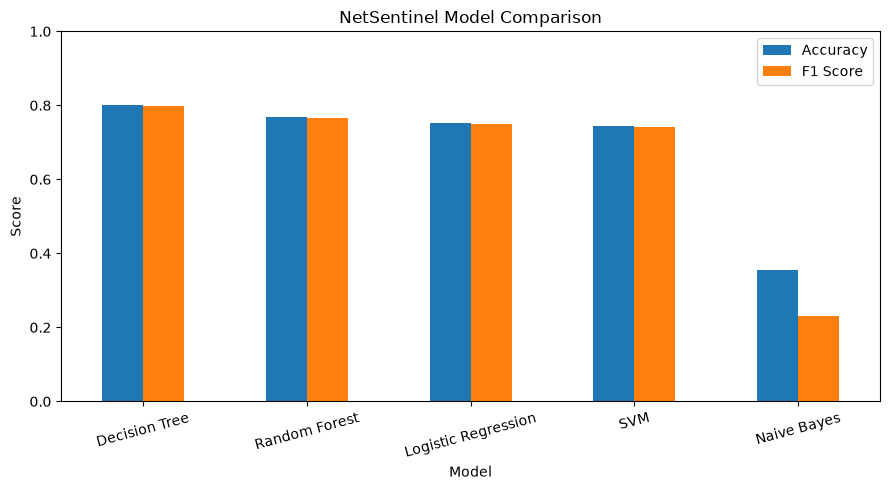

In [51]:
import matplotlib.pyplot as plt

results_df.plot(
    x="Model",
    y=["Accuracy", "F1 Score"],
    kind="bar",
    figsize=(9, 5)
)

plt.title("NetSentinel Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

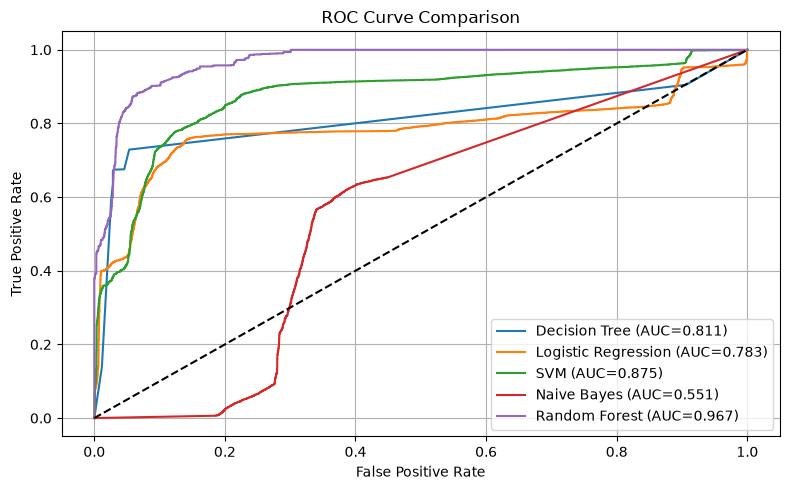

In [63]:
plt.figure(figsize=(8, 5))

models = [
    ("Decision Tree", model),
    ("Logistic Regression", lr_model),
    ("SVM", svm_model),
    ("Naive Bayes", nb_model),
    ("Random Forest", rf_model)
]

for name, m in models:
    pred = m.transform(test)

    if name == "SVM":
        score_col = "rawPrediction"
    else:
        score_col = "probability"

    data = pred.select(
        "label",
        vector_to_array(score_col)[1].alias("score")
    ).toPandas()

    fpr, tpr, _ = roc_curve(data["label"], data["score"])
    score = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{name} (AUC={score:.3f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.grid()
plt.show()

Find the best model

In [52]:
best_model = results_df.iloc[0]

print("Best model:", best_model["Model"])
print("Accuracy:", best_model["Accuracy"])
print("F1 Score:", best_model["F1 Score"])

Best model: Decision Tree
Accuracy: 0.8003
F1 Score: 0.7991


In [70]:
tree = model.stages[-1]

importance = tree.featureImportances
feature_names = assembler.getInputCols()

for i in range(len(feature_names)):
    print(feature_names[i], ":", round(float(importance[i]), 4))

duration : 0.0027
src_bytes : 0.7272
dst_bytes : 0.0122
land : 0.0
wrong_fragment : 0.026
urgent : 0.0
hot : 0.0211
num_failed_logins : 0.0001
logged_in : 0.0001
num_compromised : 0.0
root_shell : 0.0002
su_attempted : 0.0001
num_root : 0.0
num_file_creations : 0.0005
num_shells : 0.0
num_access_files : 0.0001
num_outbound_cmds : 0.0
is_host_login : 0.0
is_guest_login : 0.0
count : 0.0023
srv_count : 0.0
serror_rate : 0.0004
srv_serror_rate : 0.0
rerror_rate : 0.0
srv_rerror_rate : 0.0
same_srv_rate : 0.0001
diff_srv_rate : 0.0002
srv_diff_host_rate : 0.0
dst_host_count : 0.0033
dst_host_srv_count : 0.0005
dst_host_same_srv_rate : 0.0288
dst_host_diff_srv_rate : 0.0006
dst_host_same_src_port_rate : 0.012
dst_host_srv_diff_host_rate : 0.0126
dst_host_serror_rate : 0.0004
dst_host_srv_serror_rate : 0.0014
dst_host_rerror_rate : 0.0026
dst_host_srv_rerror_rate : 0.0
protocol_vec : 0.0
service_vec : 0.0001
flag_vec : 0.0


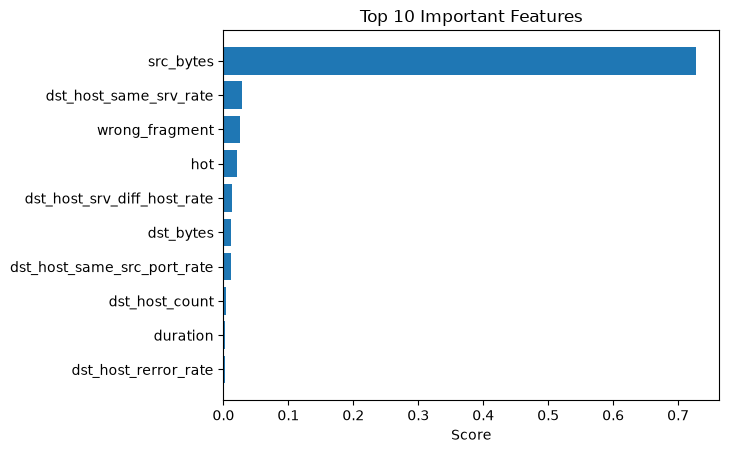

In [69]:
names = []
scores = []

for i in range(len(feature_names)):
    names.append(feature_names[i])
    scores.append(float(importance[i]))

data = pd.DataFrame({
    "Feature": names,
    "Score": scores
})

data = data.sort_values("Score", ascending=False).head(10)
data = data.sort_values("Score")

plt.barh(data["Feature"], data["Score"])
plt.title("Top 10 Important Features")
plt.xlabel("Score")
plt.show()

#### Analyze normal traffic vs attack traffic
Count normal traffic and attack traffic

In [71]:
from pyspark.sql.functions import col, when

traffic = train_df.withColumn(
    "Traffic",
    when(col("attack") == "normal", "Normal").otherwise("Attack")
)

traffic.groupBy("Traffic").count().show()

+-------+-----+
|Traffic|count|
+-------+-----+
| Attack|58630|
| Normal|67343|
+-------+-----+



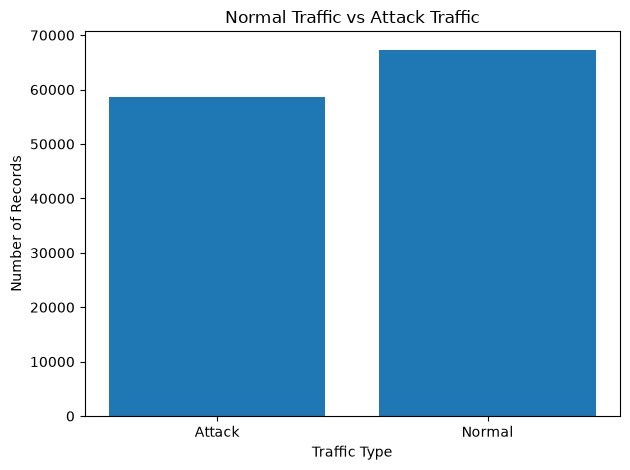

In [72]:
import matplotlib.pyplot as plt

counts = traffic.groupBy("Traffic").count().toPandas()

plt.bar(counts["Traffic"], counts["count"])
plt.title("Normal Traffic vs Attack Traffic")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

Show the most common attack types

In [73]:
train_df.filter(
    col("attack") != "normal"
).groupBy("attack").count().orderBy(
    "count", ascending=False
).show(10)

+-----------+-----+
|     attack|count|
+-----------+-----+
|    neptune|41214|
|      satan| 3633|
|    ipsweep| 3599|
|  portsweep| 2931|
|      smurf| 2646|
|       nmap| 1493|
|       back|  956|
|   teardrop|  892|
|warezclient|  890|
|        pod|  201|
+-----------+-----+
only showing top 10 rows

